In [ ]:

from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/epidemiology.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/epidemiology.csv'

In [ ]:
print(df.shape)

(12525825, 10)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12525825 entries, 0 to 12525824
Data columns (total 10 columns):
 #   Column                Dtype  
---  ------                -----  
 0   date                  object 
 1   location_key          object 
 2   new_confirmed         float64
 3   new_deceased          float64
 4   new_recovered         float64
 5   new_tested            float64
 6   cumulative_confirmed  float64
 7   cumulative_deceased   float64
 8   cumulative_recovered  float64
 9   cumulative_tested     float64
dtypes: float64(8), object(2)
memory usage: 955.6+ MB
None


In [ ]:
print(df.dtypes)

date                     object
location_key             object
new_confirmed           float64
new_deceased            float64
new_recovered           float64
new_tested              float64
cumulative_confirmed    float64
cumulative_deceased     float64
cumulative_recovered    float64
cumulative_tested       float64
dtype: object


In [ ]:
print(df['location_key'].nunique())
print(df['date'].min(), df['date'].max())

20905
2019-12-31 2022-12-30


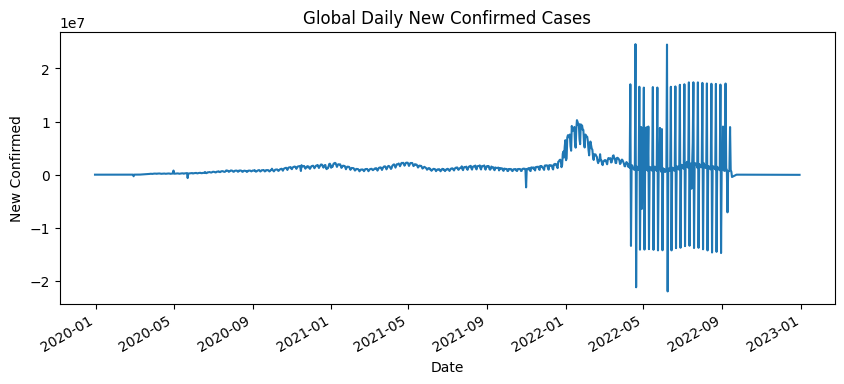

In [ ]:
import matplotlib.pyplot as plt


daily = df.groupby('date')['new_confirmed'].sum()
daily.index = pd.to_datetime(daily.index)

plt.figure(figsize=(10,4))
daily.plot()
plt.title('Global Daily New Confirmed Cases')
plt.xlabel('Date')
plt.ylabel('New Confirmed')
plt.show()

In [ ]:
peak_day = df.groupby('date')['new_confirmed'].sum().idxmax()
peak_value = df.groupby('date')['new_confirmed'].sum().max()
print(f"Peak day: {peak_day}, Global new cases: {peak_value:,.0f}")

# Which country drove it
peak_country = df[df['date'] == peak_day].sort_values('new_confirmed', ascending=False).head(5)
print(peak_country[['location_key', 'new_confirmed']])

Peak day: 2022-04-19, Global new cases: 24,583,461
        location_key  new_confirmed
8994707        NL_ZH      4997185.0
8896583        NL_NH      3889679.0
8844292        NL_NB      3655931.0
8762646        NL_GE      2917334.0
8959488        NL_UT      1965623.0
